In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
# sys.path.append("..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg


from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')


from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

# Get the parent directory path
parent_dir = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Add the parent directory to sys.path
sys.path.append(parent_dir)

from msolver import MMGKS, IASGKS

from pinv import CGWeightedNeumann2DPinvOperatorGPU

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Test problem

In [2]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 50
noise_percent = 0.03 # percent of maximum of noiseless signal A x_true
N = 100

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.03
Noise stdev: 0.8010007095336914
Noise var: 0.6416021366734771
Underdetermined rate: 0.705


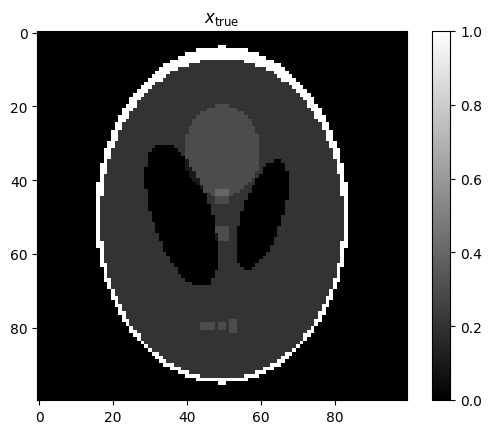

In [3]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

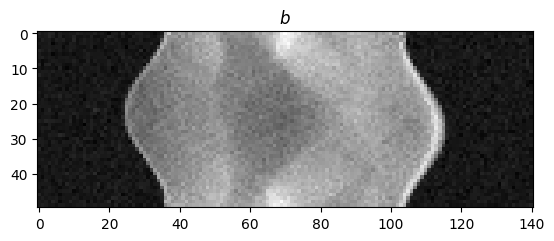

In [4]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

In [5]:
# fbp_recon = Tomo.A.reconstruct("SIRT", noisy_signal, iterations=200)
fbp_recon = Tomo.A.reconstruct("FBP", noisy_signal, iterations=1)

Error: FBP currently only supports parallel projection geometries.


AstraError: Unable to initialize algorithm: FBP currently only supports parallel projection geometries.

In [6]:
plt.imshow(np.clip(fbp_recon, a_min=0.0, a_max=None), cmap=CMAP)
plt.colorbar()
plt.show()

NameError: name 'fbp_recon' is not defined

In [15]:
# W = np.ones(n)/np.linalg.norm(np.ones(n))
# W = jlinops.MatrixLinearOperator(W)

# R = jlinops.Neumann2D(img_shape)
# def Rpinv_factory(theta, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=1.0/np.sqrt(theta), tol=1e-4, *args, **kwargs)

# #tol = 1e-2
# pdata = {
#     "W": W,
#     "Rpinv_factory": Rpinv_factory,
# }

# # Initialize everything at the least-squares reconstruction?
# x0, _ = sp_cg( (F.T @ F) + 7*1e2*(R.T @ R), F.T @ noisy_signal, tol=1e-5  )
# x0 = np.clip(x0, a_min=0.0, a_max=None)

# plt.imshow(x0.reshape(img_shape), cmap=CMAP)
# plt.colorbar()
# plt.show()

# GKS method (GKS)

In [7]:
q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [8]:
jlinops.build_neumann2d_sparse_matrix(img_shape)

<COOrdinate sparse matrix of dtype 'float64'
	with 39600 stored elements and shape (20000, 10000)>

In [9]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None


K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


#err_norm_sq = len(b) # in expectation


# Build solver
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [10]:
data = mmgks_solver.solve(n_iter=80, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
4.688154276143019
7.00629794353808
7.9287657666768565
8.53920098170007
8.940463861744123
9.404132776548467
9.662854878180282
9.849120198663913
10.070558480737441
10.32837478918414
10.612946633883803
10.750820590199119
10.820018097937297
10.885352694048592
10.899380475403214
10.908362977083979
10.907997729392171
10.902563263775503
10.905353151473896
10.911477860579872
10.91637592760587
10.908041994224416
10.906885736537157
10.902253480509158
10.89824793968627
10.89809932648048
10.91081891616168
10.933066240539285
10.941578428396252
10.9473706153102
10.949244249441719
10.953298609381106
10.952094451509664
10.950403695923612
10.948691579262183
10.94740821858655
10.940439626278046
10.935221312054926
10.927562624120739
10.928567374235696
10.9382128671141
10.93926442783824
10.940040349932898
10.93677725237127
10.931353334738343
10.938710511997273
10.951521117343734
10.94309711720869
10.921518041986731
10.898722312114694
10.878229973890129
10.869501411012019
10.859614547893518
10.859062

In [37]:
pdata = mmgks_solver.solve_with_priorconditioning(n_iter=45, init_dim=3, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.02})

AttributeError: 'CGPreconditionedPinvModOperator' object has no attribute 'kwargs'

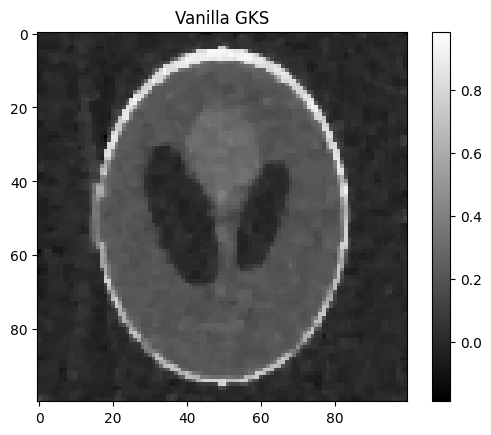

In [26]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

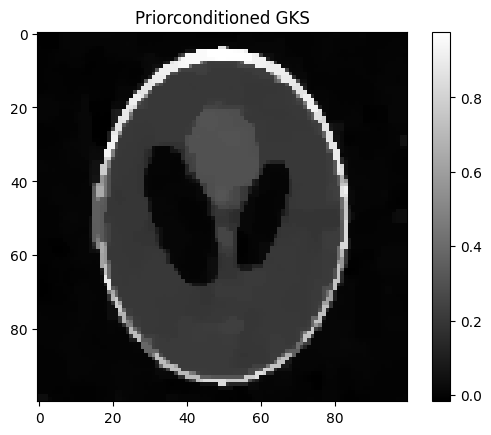

In [27]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

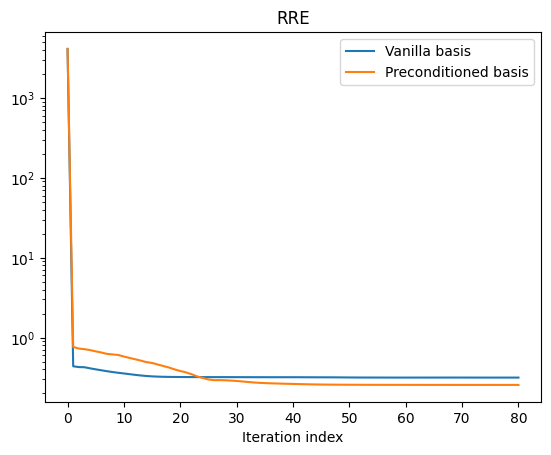

In [28]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

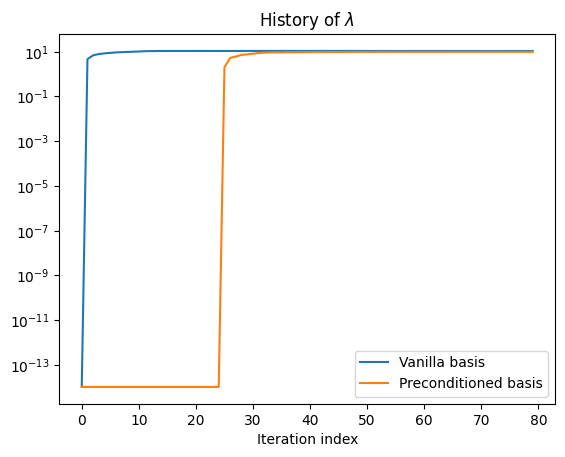

In [29]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

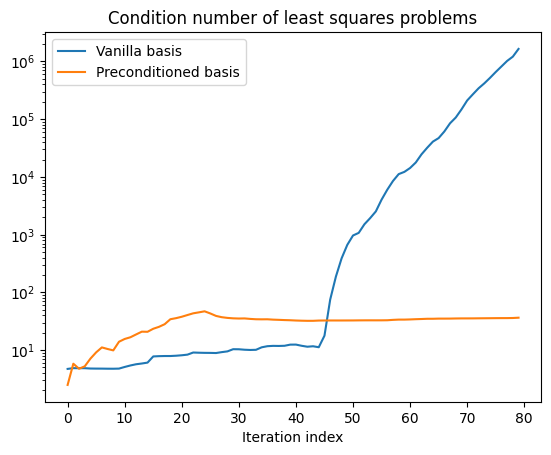

In [30]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Basis plotting code

In [54]:
from matplotlib.backends.backend_pdf import PdfPages

In [55]:
images = [ data["V"][:,j].reshape((nx,ny)) for j in range(data["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_mm_vanilla_basis.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

In [56]:
# Create a PDF file
pdf_filename = "tomo_mm_preconditioned_basis.pdf"
images = [ ( pdata["V"][:nx*ny,j].reshape((nx,ny)), pdata["V"][nx*ny:,j].reshape((nx,ny))   ) for j in range(pdata["V"].shape[1]) ]
with PdfPages(pdf_filename) as pdf:
    for i, (im1, im2) in enumerate(images):
        plt.figure(figsize=(10, 5))  # Create a figure with an appropriate size
        
        # Plot the first image (im1)
        plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
        plt.imshow(im1, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Vertical portion of basis vector, {i+1}")

        # Plot the second image (im2)
        plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
        plt.imshow(im2, cmap='plasma', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Horizontal portion of basis vector, {i+1}")
        
        # Save the current figure to the PDF
        pdf.savefig()
        plt.close()  # Close the figure to free up memory

print(f"Paired plots saved to {pdf_filename}")

Paired plots saved to tomo_mm_preconditioned_basis.pdf


In [57]:
images = [ (pdata["Lopinv"] @ pdata["V"][:,j]).reshape((nx,ny)) for j in range(pdata["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_mm_preconditioned_basis_transformed.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

# Vanilla GKS

In [58]:
from msolver import VanillaGKS

In [59]:
vgks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [60]:
vdata = vgks_solver.solve(n_iter=80, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
39.74925698834014
51.555147006282375
51.9776537180845
52.01917618283423
54.31608689502763
54.926859456190236
54.85031986336683
54.68977571718614
54.567205761387434
54.56899194279625
54.61103103038499
54.62549074376582
54.62036816241674
54.616606803497085
54.627969332254025
54.62773441235738
54.62419985286685
54.624176332194814
54.6249550931676
54.62517971775933
54.62511558020086
54.62521973607675
54.62524826499882
54.625216317601534
54.62517887132189
54.62518709120191
54.62519645337469
54.62519255908676
54.62519272096456
54.625197616533875
54.625195797671864
54.625193618576006
54.62519477005314
54.62519476562782
54.625194785080765
54.62519475786732
54.625194791002116
54.625194796135354
54.625194882545
54.62519465321533
54.62519497387251
54.6251950722617
54.62519500943127
54.62519499634609
54.6251949812602
54.62519475359726
54.62519505719461
54.625194504654004
54.62519410477593
54.62519372193581
54.625193200181975
54.62519427464434
54.625194903892314
54.6251941033002
54.6251940250

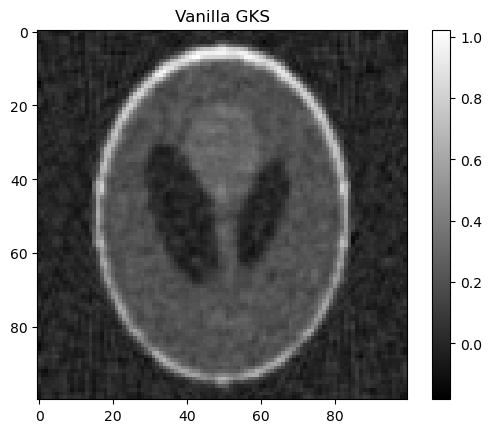

In [61]:
plt.imshow(vdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

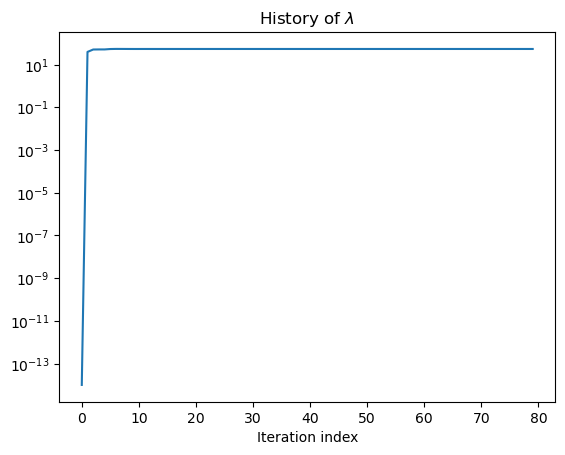

In [62]:
plt.semilogy(vdata["lambda_history"], label="Vanilla basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
# plt.legend()
plt.show()

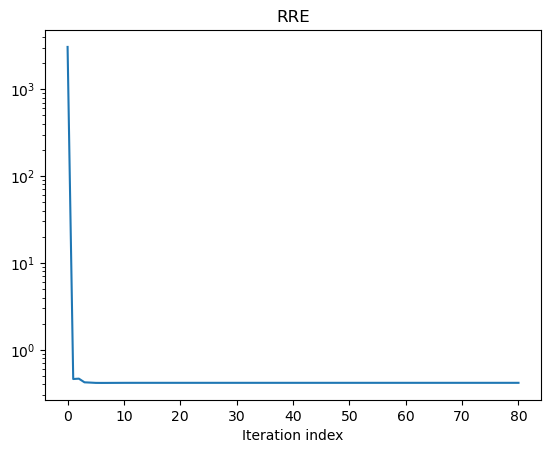

In [63]:
plt.semilogy(vdata["rre_history"], label="Vanilla basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.show()

# IAS?

In [64]:
weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [65]:
# Build solver
iasgks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [77]:
data = iasgks_solver.solve(n_iter=120, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
15.899702795336031
27.778113250979434
33.459792865267254
34.698417199629986
38.45544979717724
41.62128765784354
43.50525399167222
44.34171096681398
44.75646112942147
45.48688233734846
47.13133754792766
48.089378816345125
48.60414022954349
49.24072801354468
49.888304973959244
49.980123374444794
50.075732185704645
50.23005414236805
50.35216744596264
50.401642046052295
50.425641689904346
50.446342358907756
50.45878005000049
50.48233467149356
50.47896075832558
50.46736206823357
50.46318012698006
50.46823531141251
50.47237093826324
50.47695885381585
50.48952481430539
50.48354349524511
50.48651847991498
50.499688665961855
50.48499023275941
50.45349113610581
50.44730286169357
50.43158289481291
50.475525015216974
50.478665563865384
50.4848573601377
50.529014995459235
50.55556710967949
50.56406306541455
50.59536852077163
50.584705481010765
50.581712331703145
50.66515563675604
50.71055509557241
50.7004949472977
50.765444183577834
50.76094708304415
50.77855439926423
50.8047474417784
50.8098

In [78]:
pdata = iasgks_solver.solve_with_priorconditioning(n_iter=120, init_dim=8, x0=data["x"], lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

1
[ -26.39072647  -22.64185451  -14.9824518  ... -119.04651418  -55.83180608
    0.        ]
2
[-3.99218332e-04 -4.04044181e-04 -3.93355072e-04 ...  7.25725146e-05
  5.09778228e-05  0.00000000e+00]
3
[-0.00038891 -0.00040148 -0.00038768 ...  0.00031863  0.00017633
  0.        ]
4
[-0.00038502 -0.00039883 -0.00038435 ...  0.00035756  0.00019604
  0.        ]
5
[-0.0003844  -0.0003984  -0.00038381 ...  0.00036411  0.00019934
  0.        ]
6
[-0.00038433 -0.00039836 -0.00038376 ...  0.00036542  0.00019999
  0.        ]
7
[-0.00038434 -0.00039836 -0.00038377 ...  0.00036587  0.00020022
  0.        ]


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
7.51188514435953
7.485032609282239
11.891708298793025
14.812758802318069
17.756502610108562
23.038061394135173
27.058008254921297
30.279228682418243
33.22294064880329
35.80603826069207
37.996557188698795
40.362107877050974
42.1623532370212
43.93419875108263
46.05913834777149
48.37889957036516
50.77251760401588
53.1260350043488
55.325711032775075
57.30866312486241
58.40595347346614
59.16469439514789
59.864426662476944
60.937477450508794
62.13823318164218
63.52952341285692
64.8560415171981
66.21363074157162
67.5570078070648
68.7581519546176
69.77012885477453
70.75382856482507
71.5584933216755
72.37470086608364
73.16469220210024
73.90487411407213
74.5035764194741
75.00286857414325
75.53617522644292
76.03685971168346
76.44525229581373
76.80271195348095
77.29151477116379
77.70507036489852
78.06530440758738
78.4698374459147
78

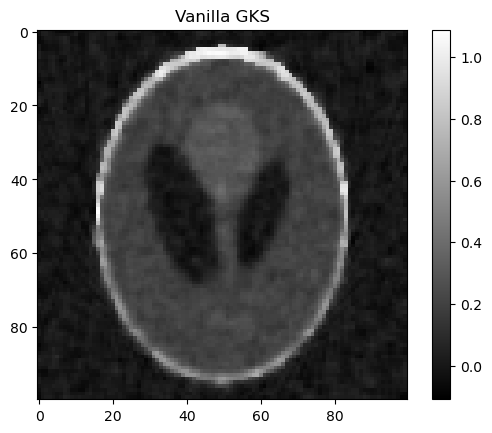

In [84]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

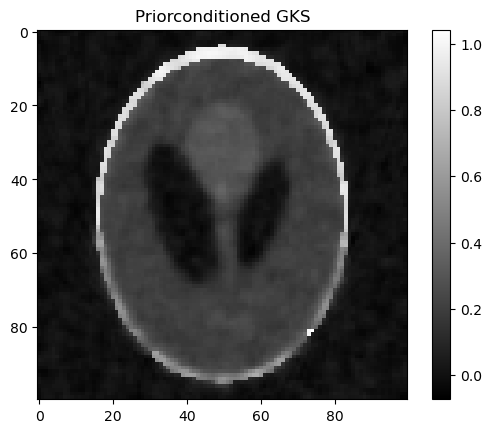

In [85]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

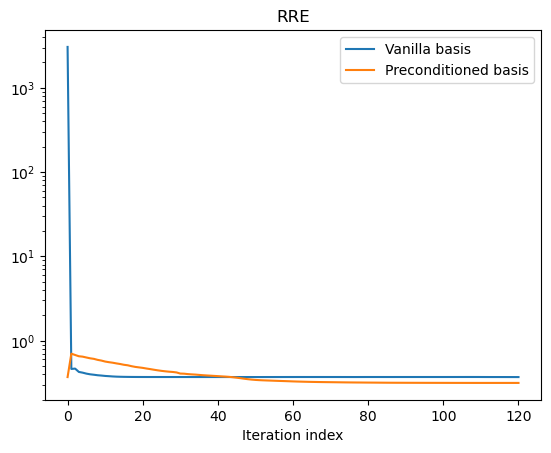

In [86]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

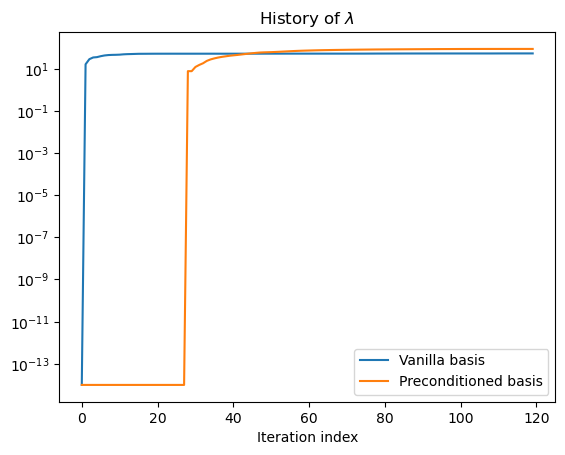

In [87]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

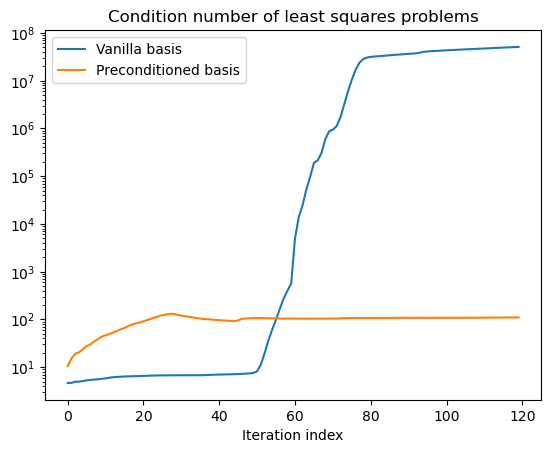

In [88]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [89]:
images = [ data["V"][:,j].reshape((nx,ny)) for j in range(data["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_ias_vanilla_basis.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

In [90]:
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis.pdf"
images = [ ( pdata["V"][:nx*ny,j].reshape((nx,ny)), pdata["V"][nx*ny:,j].reshape((nx,ny))   ) for j in range(pdata["V"].shape[1]) ]
with PdfPages(pdf_filename) as pdf:
    for i, (im1, im2) in enumerate(images):
        plt.figure(figsize=(10, 5))  # Create a figure with an appropriate size
        
        # Plot the first image (im1)
        plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
        plt.imshow(im1, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Vertical portion of basis vector, {i+1}")

        # Plot the second image (im2)
        plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
        plt.imshow(im2, cmap='plasma', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Horizontal portion of basis vector, {i+1}")
        
        # Save the current figure to the PDF
        pdf.savefig()
        plt.close()  # Close the figure to free up memory

print(f"Paired plots saved to {pdf_filename}")

Paired plots saved to tomo_ias_preconditioned_basis.pdf


In [91]:
images = [ (pdata["Lopinv"] @ pdata["V"][:,j]).reshape((nx,ny)) for j in range(pdata["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis_transformed.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues